In [28]:
import sys
print(sys.executable)

/Users/katttmar/Downloads/Segundo_Examen_Parcial_ML_2026_2_v6_material/.venv312/bin/python


In [42]:

RESULTS_DIR = ROOT / "resultados"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Las gráficas se guardarán en:", RESULTS_DIR)

Las gráficas se guardarán en: /Users/katttmar/Downloads/Segundo_Examen_Parcial_ML_2026_2_v6_material/resultados



# Segundo examen parcial: Introducción al Machine Learning

## Regresión polinomial, riesgo empírico y sensibilidad muestral

**Objetivo:** estudiar modelos de regresión polinomial de diferentes grados, comparar el riesgo de entrenamiento con el riesgo de validación y analizar cómo cambia el modelo al utilizar diferentes muestras de entrenamiento.

Se trabajará con tres conjuntos de entrenamiento (`train_A`, `train_B` y `train_C`) y un conjunto de validación independiente (`validation`).

**Criterio metodológico:** el conjunto de validación se utilizará exclusivamente para evaluar los modelos, no para entrenarlos.


In [30]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Identificar la carpeta principal del proyecto
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

# Permitir importar los módulos del proyecto
sys.path.insert(0, str(ROOT / "src"))

from parcial_ml.data import load_data
from parcial_ml.models import fit_polynomial, predict_polynomial
from parcial_ml.risk import quadratic_risk
from parcial_ml.analysis import exercise1, exercise2, exercise3

# Cargar los datos usando la función definida en data.py
train_A = load_data("train_A.csv")
train_B = load_data("train_B.csv")
train_C = load_data("train_C.csv")
validation = load_data("validation.csv")

print("Datos cargados correctamente.")
print("train_A:", train_A.shape)
print("train_B:", train_B.shape)
print("train_C:", train_C.shape)
print("validation:", validation.shape)

Datos cargados correctamente.
train_A: (30, 2)
train_B: (30, 2)
train_C: (30, 2)
validation: (140, 2)


# Ejercicio 1. Selección del grado polinomial

Se utilizará exclusivamente el conjunto `train_A` para ajustar modelos de regresión polinomial con grados entre 1 y 15.

Para cada grado se calculará el riesgo cuadrático empírico en entrenamiento y en validación. El conjunto de validación no se utilizará para ajustar los modelos.


In [43]:
# Ajustar modelos de grado 1 a 15 y calcular sus riesgos
tabla_ejercicio1, modelos_ejercicio1, mejor_train, mejor_val = exercise1()

display(tabla_ejercicio1.round(6))

,grado,riesgo_entrenamiento,riesgo_validacion
0,1,0.406777,0.510432
1,2,0.327561,0.441047
2,3,0.120407,0.200026
3,4,0.118253,0.201967
4,5,0.083426,0.161396
5,6,0.082978,0.164074
6,7,0.074472,0.184270
7,8,0.069638,0.189821
8,9,0.069184,0.188407
9,10,0.065834,0.222431


Gráfica guardada en: /Users/katttmar/Downloads/Segundo_Examen_Parcial_ML_2026_2_v6_material/resultados/ejercicio1_riesgos.png


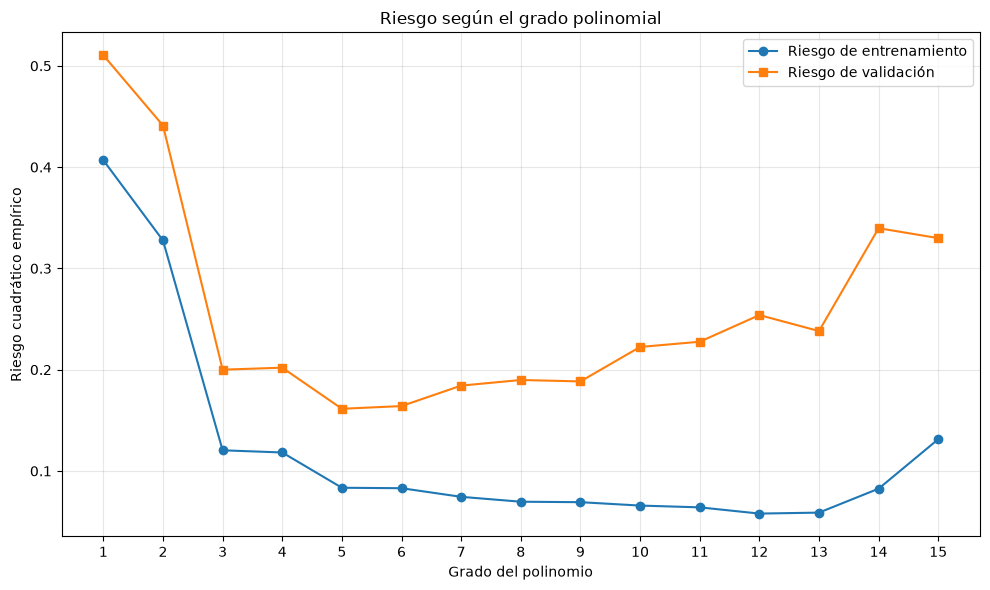

In [44]:
# EJERCICIO 1: riesgos de entrenamiento y validación

plt.figure(figsize=(10, 6))

plt.plot(
    tabla_ejercicio1["grado"],
    tabla_ejercicio1["riesgo_entrenamiento"],
    marker="o",
    label="Riesgo de entrenamiento"
)

plt.plot(
    tabla_ejercicio1["grado"],
    tabla_ejercicio1["riesgo_validacion"],
    marker="s",
    label="Riesgo de validación"
)

plt.xlabel("Grado del polinomio")
plt.ylabel("Riesgo cuadrático empírico")
plt.title("Riesgo según el grado polinomial")
plt.xticks(range(1, 16))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Guardar la gráfica
ruta_grafica = RESULTS_DIR / "ejercicio1_riesgos.png"
plt.savefig(ruta_grafica, dpi=300, bbox_inches="tight")

print("Gráfica guardada en:", ruta_grafica)

plt.show()
plt.close()

In [33]:
print("Mejor grado según entrenamiento:")
print("Grado:", int(mejor_train["grado"]))
print("Riesgo:", round(mejor_train["riesgo_entrenamiento"], 6))

print("\nMejor grado según validación:")
print("Grado:", int(mejor_val["grado"]))
print("Riesgo:", round(mejor_val["riesgo_validacion"], 6))

Mejor grado según entrenamiento:
Grado: 12
Riesgo: 0.057929

Mejor grado según validación:
Grado: 5
Riesgo: 0.161396


In [34]:
grados_comparacion = [2, 6, 15]

comparacion = tabla_ejercicio1[
    tabla_ejercicio1["grado"].isin(grados_comparacion)
].copy()

display(comparacion.round(6))

,grado,riesgo_entrenamiento,riesgo_validacion
1,2,0.327561,0.441047
5,6,0.082978,0.164074
14,15,0.131344,0.329878


### Interpretación del ejercicio 1

El riesgo de entrenamiento tiende a disminuir al aumentar el grado del polinomio, porque los modelos más complejos tienen mayor capacidad para adaptarse a los datos observados.

Sin embargo, un riesgo de entrenamiento bajo no garantiza un buen comportamiento ante datos nuevos. El riesgo de validación permite evaluar la capacidad de generalización.

En la comparación de los grados 2, 6 y 15, se espera observar:

- **Grado 2:** subajuste (*underfitting*), por su limitada capacidad para representar relaciones complejas.
- **Grado 6:** mejor equilibrio entre ajuste y generalización.
- **Grado 15:** sobreajuste (*overfitting*), si el modelo se adapta excesivamente a los datos de entrenamiento y presenta un riesgo de validación mayor.

La clasificación se debe justificar con los riesgos obtenidos en la tabla.

## Ejercicio 2. Sensibilidad a la muestra

En este ejercicio se comparan tres conjuntos de entrenamiento, `train_A.csv`, `train_B.csv` y `train_C.csv`, obtenidos bajo las mismas condiciones.

Para cada conjunto se ajustan modelos polinomiales de grados 2, 6 y 15. Posteriormente, se comparan las hipótesis aprendidas sobre una malla común de 300 puntos en el intervalo \([-2.5,2.5]\).

La variabilidad (V_d) mide cuánto cambian las predicciones de un mismo grado al cambiar la muestra de entrenamiento. También se calculará el riesgo de validación promedio de los tres modelos correspondientes a cada grado.

In [35]:
(
    grid,
    modelos_ejercicio2,
    predicciones_ejercicio2,
    predicciones_promedio,
    variabilidades,
    riesgos_validacion_promedio,
    tabla_ejercicio2
) = exercise2()

display(tabla_ejercicio2.round(6))

,grado,V_d,riesgo_validacion_promedio
0,2,0.009695,0.458920
1,6,0.014151,0.164837
2,15,0.082507,0.251828


Gráfica guardada en: /Users/katttmar/Downloads/Segundo_Examen_Parcial_ML_2026_2_v6_material/resultados/ejercicio2_hipotesis_grado_2.png


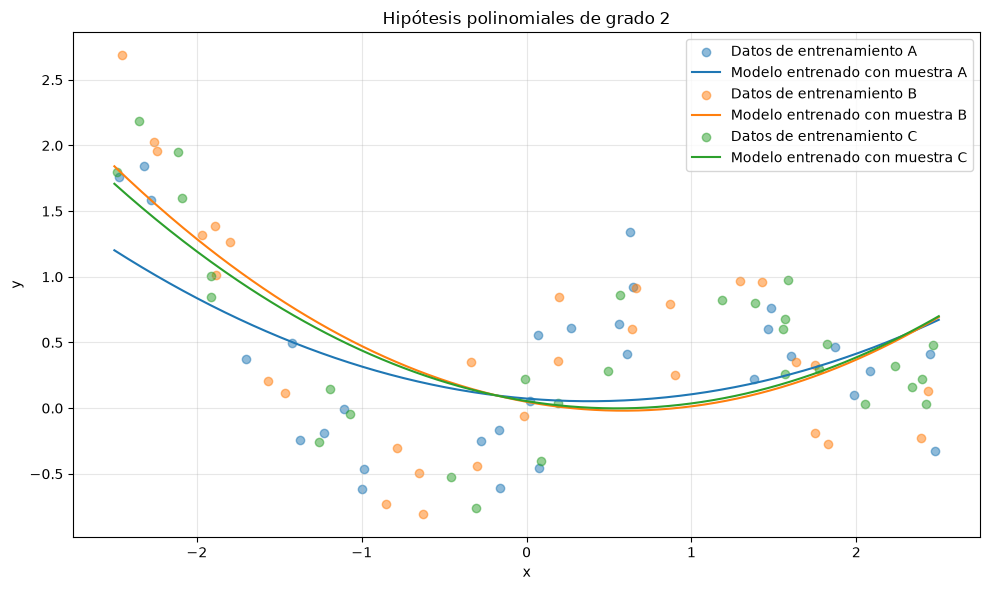

Gráfica guardada en: /Users/katttmar/Downloads/Segundo_Examen_Parcial_ML_2026_2_v6_material/resultados/ejercicio2_hipotesis_grado_6.png


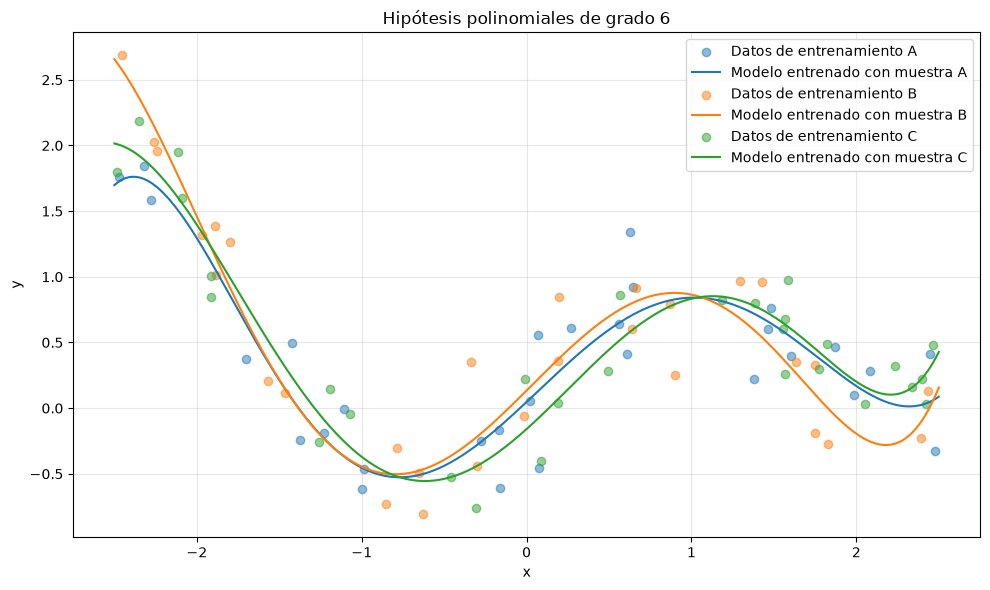

Gráfica guardada en: /Users/katttmar/Downloads/Segundo_Examen_Parcial_ML_2026_2_v6_material/resultados/ejercicio2_hipotesis_grado_15.png


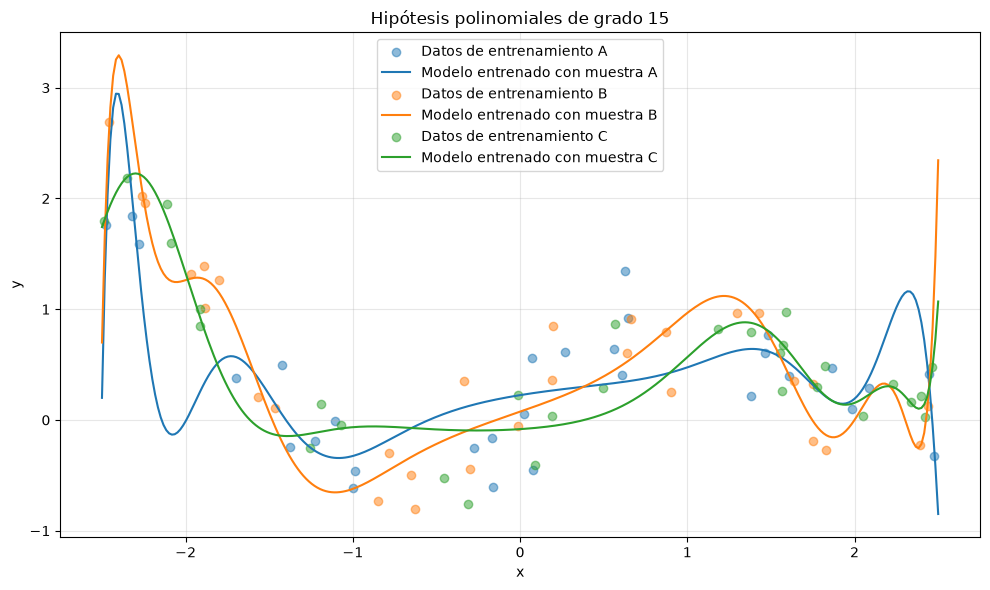

In [36]:
# EJERCICIO 2: comparar las hipótesis de las tres muestras

muestras = {
    "A": train_A,
    "B": train_B,
    "C": train_C
}

for grado in [2, 6, 15]:
    plt.figure(figsize=(10, 6))

    for nombre, datos in muestras.items():
        plt.scatter(
            datos["x"],
            datos["y"],
            alpha=0.5,
            label=f"Datos de entrenamiento {nombre}"
        )

        plt.plot(
            grid,
            predicciones_ejercicio2[grado][nombre],
            label=f"Modelo entrenado con muestra {nombre}"
        )

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Hipótesis polinomiales de grado {grado}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    # Guardar una imagen por cada grado
    nombre_archivo = f"ejercicio2_hipotesis_grado_{grado}.png"
    ruta_grafica = RESULTS_DIR / nombre_archivo

    plt.savefig(ruta_grafica, dpi=300, bbox_inches="tight")

    print("Gráfica guardada en:", ruta_grafica)

    plt.show()
    plt.close()

In [37]:
tabla_variabilidad = tabla_ejercicio2.sort_values(
    by="V_d",
    ascending=True
)

display(tabla_variabilidad.round(6))

grado_mas_estable = int(tabla_variabilidad.iloc[0]["grado"])
grado_mas_sensible = int(tabla_variabilidad.iloc[-1]["grado"])

print("Grado más estable:", grado_mas_estable)
print("Grado más sensible a la muestra:", grado_mas_sensible)

,grado,V_d,riesgo_validacion_promedio
0,2,0.009695,0.458920
1,6,0.014151,0.164837
2,15,0.082507,0.251828


Grado más estable: 2
Grado más sensible a la muestra: 15


### Interpretación del ejercicio 2

La variabilidad muestral permite estudiar la sensibilidad de los modelos ante cambios en los datos utilizados para entrenarlos.

Un valor pequeño de \(V_d\) indica que las predicciones de los modelos ajustados con las muestras A, B y C son similares. Un valor grande indica que las predicciones dependen más de la muestra utilizada.

La clasificación esperada es:

- **Grado 2:** alta tendencia al sesgo y menor sensibilidad a la muestra.
- **Grado 6:** compromiso entre capacidad de ajuste y variabilidad.
- **Grado 15:** mayor varianza y mayor sensibilidad a los cambios en la muestra.

Esta clasificación debe contrastarse con los valores numéricos de \(V_d\) y con las gráficas obtenidas.

## Ejercicio 3. Selección del modelo

En este ejercicio se selecciona un único grado entre 2, 6 y 15, considerando simultáneamente el riesgo promedio de validación y la sensibilidad a los cambios de muestra.

La selección debe priorizar un modelo que generalice adecuadamente y cuyo comportamiento sea relativamente estable al entrenarse con nuevas muestras obtenidas bajo las mismas condiciones.

In [38]:
tabla_ejercicio3 = exercise3()

display(tabla_ejercicio3.round(6))

,grado,Rval_d,V_d
0,2,0.458920,0.009695
1,6,0.164837,0.014151
2,15,0.251828,0.082507


In [39]:
# Elegir el grado 6 como compromiso entre validación y variabilidad
grado_recomendado = 6

fila_recomendada = tabla_ejercicio3[
    tabla_ejercicio3["grado"] == grado_recomendado
].iloc[0]

print("Grado recomendado:", grado_recomendado)
print(
    "Riesgo de validación promedio:",
    round(fila_recomendada["Rval_d"], 6)
)
print(
    "Variabilidad muestral:",
    round(fila_recomendada["V_d"], 6)
)

Grado recomendado: 6
Riesgo de validación promedio: 0.164837
Variabilidad muestral: 0.014151


In [40]:
grado_minimo_entrenamiento = int(mejor_train["grado"])
riesgo_minimo_entrenamiento = float(
    mejor_train["riesgo_entrenamiento"]
)

coinciden = grado_recomendado == grado_minimo_entrenamiento

print(
    "Grado recomendado por validación y variabilidad:",
    grado_recomendado
)
print(
    "Grado con menor riesgo de entrenamiento:",
    grado_minimo_entrenamiento
)
print(
    "Riesgo mínimo de entrenamiento:",
    round(riesgo_minimo_entrenamiento, 6)
)
print("¿Coinciden ambos grados?", "Sí" if coinciden else "No")

Grado recomendado por validación y variabilidad: 6
Grado con menor riesgo de entrenamiento: 12
Riesgo mínimo de entrenamiento: 0.057929
¿Coinciden ambos grados? No


In [41]:
fila_grado_6 = tabla_ejercicio1[
    tabla_ejercicio1["grado"] == 6
].iloc[0]

fila_grado_15 = tabla_ejercicio1[
    tabla_ejercicio1["grado"] == 15
].iloc[0]

print("Grado 6:")
print(
    "Riesgo de entrenamiento:",
    round(fila_grado_6["riesgo_entrenamiento"], 6)
)
print(
    "Riesgo de validación:",
    round(fila_grado_6["riesgo_validacion"], 6)
)

print("\nGrado 15:")
print(
    "Riesgo de entrenamiento:",
    round(fila_grado_15["riesgo_entrenamiento"], 6)
)
print(
    "Riesgo de validación:",
    round(fila_grado_15["riesgo_validacion"], 6)
)

print(
    "\n¿Se debe preferir siempre el grado más complejo?",
    "No"
)

Grado 6:
Riesgo de entrenamiento: 0.082978
Riesgo de validación: 0.164074

Grado 15:
Riesgo de entrenamiento: 0.131344
Riesgo de validación: 0.329878

¿Se debe preferir siempre el grado más complejo? No


### Selección del modelo

Se selecciona el **grado 6**, porque presenta el menor riesgo promedio de validación entre los tres grados considerados, con \(R_{\mathrm{val}}(6)\approx0.164837\), y una varianza \(V_6\approx0.014151\), considerablemente menor que la del grado 15.

Aunque el grado 2 presenta una varianza ligeramente inferior, su riesgo promedio de validación es mucho mayor. El grado 6 ofrece el mejor compromiso observado entre capacidad de generalización y estabilidad ante cambios en la muestra.

### Interpretación del ejercicio 3

La selección del grado polinomial debe considerar tanto el riesgo de validación como la variabilidad muestral.

El grado 15 puede alcanzar un riesgo de entrenamiento inferior al del grado 6, pero esto no implica que generalice mejor. Si el riesgo de validación aumenta, el modelo puede estar sobreajustándose.

Por tanto, no se debe elegir automáticamente el polinomio más complejo. Es necesario evaluar su comportamiento sobre datos no utilizados en el entrenamiento y considerar su sensibilidad a los cambios en la muestra.

# Conclusión 

El análisis de los modelos polinomiales muestra que aumentar la complejidad puede reducir el riesgo de entrenamiento sin mejorar necesariamente la generalización.

La comparación entre los riesgos de entrenamiento y validación permite detectar posibles situaciones de subajuste y sobreajuste. Por su parte, la variabilidad muestral permite estudiar la estabilidad de las predicciones cuando se modifica el conjunto de entrenamiento.

En conjunto, estos resultados muestran la importancia de seleccionar modelos considerando más de un criterio: un buen ajuste a los datos de entrenamiento no es suficiente para garantizar un desempeño adecuado en datos nuevos.